<!-- open-in-badges -->
[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/EAFIT-IA/si7011-DeepLearning/blob/main/sessions/06_foundation_models/notebooks/sesion_06_1_autoatencion.ipynb) [![Abrir en Kaggle](https://kaggle.com/static/images/open-in-kaggle.svg)](https://kaggle.com/kernels/welcome?src=https://github.com/EAFIT-IA/si7011-DeepLearning/blob/main/sessions/06_foundation_models/notebooks/sesion_06_1_autoatencion.ipynb) [![Abrir en Lightning Studio](https://pl-bolts-doc-images.s3.us-east-2.amazonaws.com/app-2/studio-badge.svg)](https://lightning.ai/new?repo_url=https%3A%2F%2Fgithub.com%2FEAFIT-IA%2Fsi7011-DeepLearning%2Fblob%2Fmain%2Fsessions%2F06_foundation_models%2Fnotebooks%2Fsesion_06_1_autoatencion.ipynb)

# SI7011 · Sesión 06 · 1. Autoatención: cada token lee a todos los demás
**Juan David Martínez Vargas · Universidad EAFIT**

Acompaña la **Parte 1** de las diapositivas. Construimos la autoatención desde cero, con tensores pequeños que se pueden imprimir, y comprobamos cada pieza contra la implementación de PyTorch.

| Sección | Lo que cambia | Qué mirar |
|---|---|---|
| 1 | atención **sin parámetros**: $\omega_{ij} = \mathbf x_i^\top \mathbf x_j$ | ¿a quién lee cada token? |
| 2 | proyecciones $W_Q, W_K, W_V$ | el resultado coincide con `F.scaled_dot_product_attention` |
| 3 | dividir o no por $\sqrt{d_k}$ | cuánto se satura el softmax |
| 4 | $H$ cabezas | mismos parámetros que una cabeza; coincide con `nn.MultiheadAttention` |
| 5 | máscaras de padding y causal | qué celdas quedan en 0 |
| 6 | barajar los tokens, con y sin posición | la predicción de la diapositiva 17 |
| 7 | crecer $T$ | tiempo y memoria de la matriz $T \times T$ |

**Datos:** ninguno; todo se genera aquí. Corre en CPU en menos de un minuto (Colab, Kaggle, Lightning o local).

In [1]:
import json, math, time
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F

torch.manual_seed(0)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
print('PyTorch', torch.__version__)

PyTorch 2.14.1+cu130


## 1. Atención sin parámetros
La frase de las diapositivas, cinco tokens. Cada token es un vector $\mathbf x_i \in \mathbb R^{d}$; aquí son aleatorios, como los embeddings de una red que todavía no ha entrenado. Las filas de $X$ son los tokens (sesión 03).

La versión más simple de la autoatención no tiene ningún parámetro: **comparar, normalizar, promediar** (diapositivas 6 y 8).

In [2]:
PALABRAS = ['me', 'senté', 'en', 'el', 'banco']
T, d = len(PALABRAS), 16
X = torch.randn(T, d)                       # X: (T, d), una fila por token

omega = X @ X.T                             # ω_ij = x_i^T x_j          (T, T)
A = torch.softmax(omega, dim=-1)            # A_ij = softmax_j(ω_ij)    cada fila suma 1
Y = A @ X                                   # y_i = Σ_j A_ij x_j        (T, d)

print('suma de cada fila de A:', A.sum(-1))
print('pesos de "banco" (fila 5):', [f'{p:.2f}' for p in A[4]])

suma de cada fila de A: tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000])
pesos de "banco" (fila 5): ['0.00', '0.00', '0.00', '0.00', '1.00']


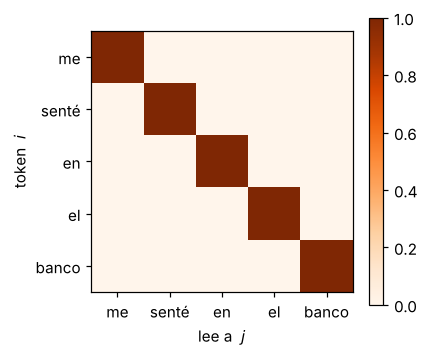

In [3]:
fig, ax = plt.subplots(figsize=(4, 3.4))
im = ax.imshow(A, cmap='Oranges', vmin=0, vmax=1)
ax.set_xticks(range(T), PALABRAS); ax.set_yticks(range(T), PALABRAS); ax.grid(False)
ax.set_xlabel('lee a  $j$'); ax.set_ylabel('token  $i$'); plt.colorbar(im, ax=ax)
plt.tight_layout(); plt.show()

La diagonal se lleva casi todo el peso: $\mathbf x_i^\top \mathbf x_i = \lVert \mathbf x_i \rVert^2$ suele ser el puntaje más grande, así que **cada token se lee a sí mismo** y $\mathbf y_i \approx \mathbf x_i$. Además, la similitud es la misma para cualquier tarea. Eso es lo que arreglan las proyecciones aprendidas (diapositiva 9).

## 2. Query, key y value
Tres proyecciones, una por rol: $Q = XW_Q$, $K = XW_K$, $V = XW_V$. En una red entrenada se aprenden; aquí son aleatorias. La fórmula de la diapositiva 11, en tres líneas, comparada con la función de PyTorch:

In [4]:
d_k = 8
W_Q, W_K, W_V = (torch.randn(d, d_k) / math.sqrt(d) for _ in range(3))

def atencion(Q, K, V, M=None):
    S = Q @ K.transpose(-2, -1) / math.sqrt(Q.shape[-1])      # S = QK^T / sqrt(d_k)    (…, T, T)
    if M is not None:
        S = S + M                                              # M: 0 permitido, -inf prohibido
    A = torch.softmax(S, dim=-1)                               # cada fila suma 1
    return A @ V, A                                            # (…, T, d_k)

Q, K, V = X @ W_Q, X @ W_K, X @ W_V
Y, A = atencion(Q, K, V)
Y_torch = F.scaled_dot_product_attention(Q, K, V)
print('¿igual a PyTorch?', torch.allclose(Y, Y_torch, atol=1e-6))
print('pesos de "banco":', [f'{p:.2f}' for p in A[4]])

¿igual a PyTorch? True
pesos de "banco": ['0.06', '0.12', '0.18', '0.10', '0.54']


Ahora el peso de "banco" se reparte: sigue poniendo una parte en sí mismo, pero ya no todo, y **cuánto** pone en cada token depende de $W_Q$ y $W_K$, es decir, de lo que la red aprenda. Con estas proyecciones aleatorias el reparto no significa nada todavía; en la figura de la diapositiva 10, pensada para ese ejemplo, "banco" mira sobre todo a "senté".

## 3. ¿Por qué dividir por $\sqrt{d_k}$?
**Predice antes de correr:** si las entradas de $\mathbf q$ y $\mathbf k$ tienen media 0 y varianza 1, ¿cómo crece la desviación estándar de $\mathbf q^\top \mathbf k$ con $d_k$?

In [5]:
filas = []
for dk in (4, 16, 64, 256):
    q, k = torch.randn(10000, dk), torch.randn(10000, dk)
    s = (q * k).sum(-1)                                        # un producto punto por par
    filas.append((dk, s.std().item(), (s / math.sqrt(dk)).std().item()))
    print(f'd_k = {dk:3d}   std(q·k) = {filas[-1][1]:5.2f}   std(q·k / sqrt(d_k)) = {filas[-1][2]:4.2f}')

d_k =   4   std(q·k) =  2.00   std(q·k / sqrt(d_k)) = 1.00
d_k =  16   std(q·k) =  3.99   std(q·k / sqrt(d_k)) = 1.00
d_k =  64   std(q·k) =  7.93   std(q·k / sqrt(d_k)) = 0.99
d_k = 256   std(q·k) = 16.10   std(q·k / sqrt(d_k)) = 1.01


La desviación crece como $\sqrt{d_k}$ (la varianza de una suma de $d_k$ términos independientes de varianza 1 es $d_k$). Lo que eso le hace al softmax: una fila de 10 puntajes con $d_k = 64$, con y sin escala.

In [6]:
torch.manual_seed(1)
dk = 64
q, K10 = torch.randn(dk), torch.randn(10, dk)
for nombre, s in [('sin escala', K10 @ q), ('con escala', K10 @ q / math.sqrt(dk))]:
    s = s.clone().requires_grad_()
    p = torch.softmax(s, -1)
    p[0].backward()                                            # ¿cuánto cambia p_0 si muevo los puntajes?
    print(f'{nombre}: peso máximo {p.max():.3f} · norma del gradiente {s.grad.norm():.4f}')

sin escala: peso máximo 0.999 · norma del gradiente 0.0000
con escala: peso máximo 0.435 · norma del gradiente 0.0185


Sin escala, un solo peso se acerca a 1 y el gradiente que llega a los puntajes es casi 0: la atención deja de aprender. Con la escala, los puntajes vuelven a tener varianza 1. Es el mismo argumento de varianza de la **inicialización** de la sesión 02.

## 4. Varias cabezas
$H$ cabezas de ancho $d_k = d/H$, cada una con sus propias $W_Q, W_K, W_V$; se concatenan y se proyectan con $W_O$ (diapositiva 14). En código, las cabezas son un `reshape`: `(B, T, d) → (B, H, T, d_k)`.

In [7]:
class MultiCabeza(nn.Module):
    def __init__(self, d, H):
        super().__init__()
        self.H, self.d_k = H, d // H                           # d_k = d / H
        self.W_Q = nn.Linear(d, d, bias=False)                 # las H matrices W_Q^(h), una al lado de la otra
        self.W_K = nn.Linear(d, d, bias=False)
        self.W_V = nn.Linear(d, d, bias=False)
        self.W_O = nn.Linear(d, d, bias=False)

    def forward(self, X, M=None):                              # X: (B, T, d)
        B, T, d = X.shape
        separar = lambda Z: Z.view(B, T, self.H, self.d_k).transpose(1, 2)    # (B, H, T, d_k)
        Q, K, V = separar(self.W_Q(X)), separar(self.W_K(X)), separar(self.W_V(X))
        Y, A = atencion(Q, K, V, M)                            # las H cabezas en paralelo
        Y = Y.transpose(1, 2).reshape(B, T, d)                 # concatenar: (B, T, H·d_k)
        return self.W_O(Y), A

d, H = 64, 4
mha = MultiCabeza(d, H)
print('parámetros:', sum(p.numel() for p in mha.parameters()), '= 4d² =', 4 * d * d)

parámetros: 16384 = 4d² = 16384


Mismos parámetros que una sola cabeza de ancho $d$: $4d^2$. Comprobamos contra `nn.MultiheadAttention` copiando los pesos (PyTorch guarda $W_Q, W_K, W_V$ apiladas y traspuestas en `in_proj_weight`):

In [8]:
ref = nn.MultiheadAttention(d, H, bias=False, batch_first=True)
with torch.no_grad():
    ref.in_proj_weight.copy_(torch.cat([mha.W_Q.weight, mha.W_K.weight, mha.W_V.weight]))
    ref.out_proj.weight.copy_(mha.W_O.weight)
Xb = torch.randn(2, 7, d)
Y_nuestro, A_nuestra = mha(Xb)
Y_ref, _ = ref(Xb, Xb, Xb)
print('¿igual a nn.MultiheadAttention?', torch.allclose(Y_nuestro, Y_ref, atol=1e-5))
print('una matriz de atención por cabeza:', tuple(A_nuestra.shape), '= (B, H, T, T)')

¿igual a nn.MultiheadAttention? True
una matriz de atención por cabeza: (2, 4, 7, 7) = (B, H, T, T)


## 5. Máscaras
$A = \mathrm{softmax}(S + M)$ con $M_{ij} = -\infty$ donde $i$ no debe leer a $j$ (diapositiva 16). Usamos la frase con dos posiciones de relleno al final, como en un lote con frases de distinta longitud (sesión 05).

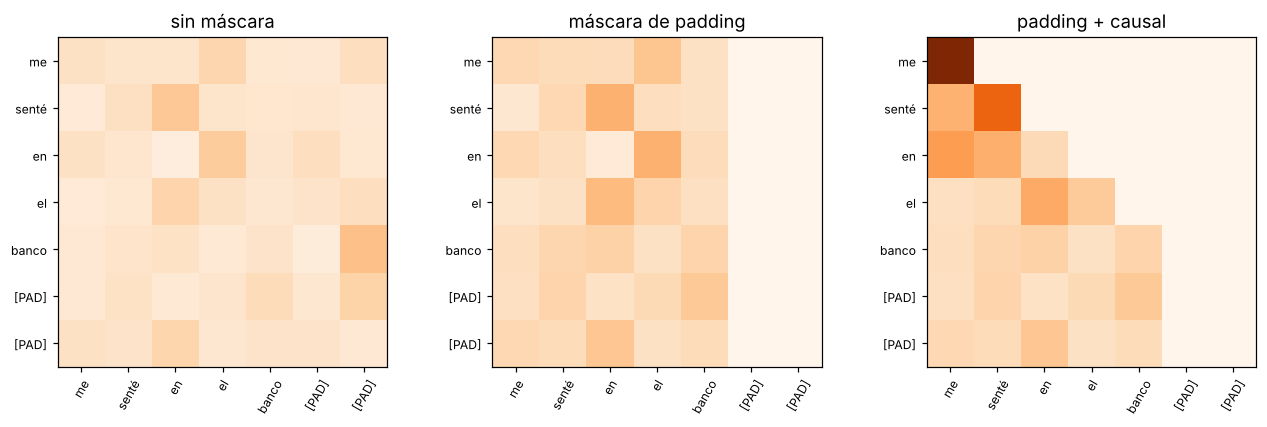

peso total puesto en [PAD] con la máscara: 0.0
peso total puesto en el futuro con la máscara causal: 0.0


In [9]:
torch.manual_seed(2)
TOKENS = PALABRAS + ['[PAD]', '[PAD]']
T7 = len(TOKENS)
X7 = torch.randn(1, T7, d)
cabeza = MultiCabeza(d, 1)                                    # una cabeza, para ver una sola matriz

es_pad = torch.tensor([t == '[PAD]' for t in TOKENS])
M_pad = torch.zeros(T7, T7).masked_fill(es_pad[None, :], float('-inf'))         # nadie lee [PAD]
M_causal = torch.zeros(T7, T7).masked_fill(torch.ones(T7, T7).triu(1).bool(), float('-inf'))   # j > i prohibido

with torch.no_grad():
    A_sin = cabeza(X7)[1][0, 0]
    A_pad = cabeza(X7, M_pad)[1][0, 0]
    A_cau = cabeza(X7, M_pad + M_causal)[1][0, 0]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, A_, t in zip(axes, [A_sin, A_pad, A_cau], ['sin máscara', 'máscara de padding', 'padding + causal']):
    ax.imshow(A_, cmap='Oranges', vmin=0, vmax=1)
    ax.set_xticks(range(T7), TOKENS, rotation=60, fontsize=8); ax.set_yticks(range(T7), TOKENS, fontsize=8)
    ax.set_title(t); ax.grid(False)
plt.tight_layout(); plt.show()
print('peso total puesto en [PAD] con la máscara:', A_pad[:, es_pad].sum().item())
print('peso total puesto en el futuro con la máscara causal:', A_cau.triu(1).sum().item())

$e^{-\infty} = 0$: las celdas prohibidas reciben peso **exactamente** 0 y cada fila sigue sumando 1. Con la máscara causal, la fila de "me" solo puede leer a "me": la primera palabra no tiene pasado.

Las filas de `[PAD]` también se calculan (leen a los tokens reales); su salida se ignora después, en la pérdida.

## 6. Barajar los tokens
**La predicción de la diapositiva 17.** Una capa de atención **sin** información de posición. Le damos la frase y luego los mismos tokens en otro orden. ¿Qué pasa con las salidas, sin máscara y con máscara causal?

In [10]:
torch.manual_seed(3)
X5 = torch.randn(1, T, d)
orden = torch.tensor([4, 2, 0, 3, 1])                         # "banco en me el senté"
capa = MultiCabeza(d, H)

def salidas(Xin, M=None):
    with torch.no_grad():
        return capa(Xin, M)[0][0]

M5 = torch.zeros(T, T).masked_fill(torch.ones(T, T).triu(1).bool(), float('-inf'))
Y1, Y2 = salidas(X5), salidas(X5[:, orden])
Y1c, Y2c = salidas(X5, M5), salidas(X5[:, orden], M5)
print('sin máscara: ¿salidas = las mismas, barajadas?', torch.allclose(Y2, Y1[orden], atol=1e-6))
print('causal:      ¿salidas = las mismas, barajadas?', torch.allclose(Y2c, Y1c[orden], atol=1e-6))

sin máscara: ¿salidas = las mismas, barajadas? True
causal:      ¿salidas = las mismas, barajadas? False


Sin máscara, la autoatención es **equivariante a permutaciones**: barajar la entrada solo baraja la salida. Para ella, "me senté en el banco" y "banco en me el senté" son el mismo **conjunto** de tokens (la prueba de permutación de la sesión 03).

Con la máscara causal las salidas cambian, pero solo porque cambia **qué** tokens ve cada posición, no **dónde** están. Para que el orden cuente hay que sumar un vector por posición, $\mathbf x_i + \mathbf p_i$ (diapositiva 18):

In [11]:
P = torch.randn(1, T, d) * 0.5                                 # un vector p_i por posición (aprendido; aquí aleatorio)
Z1, Z2 = salidas(X5 + P), salidas(X5[:, orden] + P)           # p_i se suma a lo que esté en la posición i
print('con posición: ¿salidas = las mismas, barajadas?', torch.allclose(Z2, Z1[orden], atol=1e-6))
print('salida de "banco": diferencia entre los dos órdenes')
print(f'  sin posición {(Y2[0] - Y1[4]).norm():.4f}    con posición {(Z2[0] - Z1[4]).norm():.4f}')

con posición: ¿salidas = las mismas, barajadas? False
salida de "banco": diferencia entre los dos órdenes
  sin posición 0.0000    con posición 0.4989


In [12]:
# Lo que lee la figura S06-F06 (make_s06_figuras_notebooks.py)
np.savez('atencion_mascaras.npz', tokens=np.array(TOKENS), A_sin=A_sin.numpy(), A_pad=A_pad.numpy(),
         A_causal=A_cau.numpy(), palabras=np.array(PALABRAS), orden=orden.numpy(),
         Y1=Y1.numpy(), Y2=Y2.numpy(), Z1=Z1.numpy(), Z2=Z2.numpy())

## 7. El costo de la atención
Cada cabeza de cada capa calcula una matriz $T \times T$ (diapositiva 21). Medimos el tiempo de una capa de 4 cabezas con $d = 64$ y la memoria de sus matrices de atención en `float32`, para contextos cada vez más largos.

In [13]:
capa = MultiCabeza(64, 4).eval()
costo = []
for T_ in (128, 256, 512, 1024, 2048):
    Xc = torch.randn(1, T_, 64)
    with torch.no_grad():
        capa(Xc)                                                # calentar
        t0 = time.perf_counter()
        for _ in range(3):
            capa(Xc)
    ms = (time.perf_counter() - t0) / 3 * 1000
    mb = 4 * T_ * T_ * 4 / 2**20                                # H matrices de T×T, 4 bytes cada número
    costo.append({'T': T_, 'ms': ms, 'MB_atencion': mb})
    print(f'T = {T_:5d}   {ms:8.1f} ms   matrices de atención {mb:7.1f} MB')
json.dump(costo, open('costo_atencion.json', 'w'), indent=1)

T =   128        0.4 ms   matrices de atención     0.2 MB
T =   256        0.9 ms   matrices de atención     1.0 MB
T =   512        3.2 ms   matrices de atención     4.0 MB


T =  1024       38.3 ms   matrices de atención    16.0 MB


T =  2048      144.4 ms   matrices de atención    64.0 MB


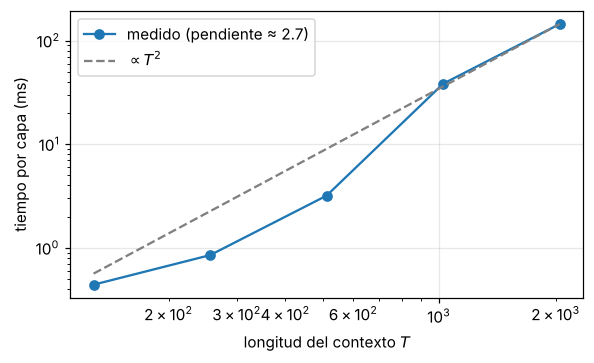

In [14]:
Ts = np.array([c['T'] for c in costo]); ms = np.array([c['ms'] for c in costo])
pend = np.polyfit(np.log(Ts[2:]), np.log(ms[2:]), 1)[0]
fig, ax = plt.subplots(figsize=(5.5, 3.4))
ax.loglog(Ts, ms, 'o-', label=f'medido (pendiente ≈ {pend:.1f})')
ax.loglog(Ts, ms[-1] * (Ts / Ts[-1])**2, '--', color='gray', label='$\\propto T^2$')
ax.set_xlabel('longitud del contexto $T$'); ax.set_ylabel('tiempo por capa (ms)'); ax.legend()
plt.tight_layout(); plt.show()

La memoria de las matrices crece exactamente como $T^2$: duplicar el contexto la multiplica por 4. El tiempo crece por lo menos así. Con $T$ pequeño pesa la parte que crece como $T$ (las proyecciones, $T d^2$); con $T$ grande, en CPU, las matrices dejan de caber en la memoria caché y el salto puede ser **mayor** que 4 (mira tus números entre 512 y 1024; dependen de tu máquina). Es el precio de que cualquier token pueda leer directamente a cualquier otro (diapositivas 21 y 22).

## Tu turno · 10 minutos
1. En la sección 1, multiplica `X` por 0.1 antes de calcular `omega`. ¿Sigue cada token leyéndose a sí mismo? ¿Por qué?
2. En la sección 3, ¿qué pasa con el peso máximo y el gradiente si divides por $d_k$ en lugar de $\sqrt{d_k}$?
3. En la sección 5, usa solo la máscara causal (sin la de padding). ¿Qué filas leen `[PAD]` ahora? ¿Importa?
4. En la sección 6, cambia `orden` por una permutación que deje "banco" en la última posición. ¿Cambia la salida de "banco" con la máscara causal? ¿Y sin máscara?

**Para pensar.** La máscara causal hace que la salida dependa de qué tokens hay antes, pero no de en qué posición está cada uno. Con la máscara causal y sin $\mathbf p_i$, ¿puede la red distinguir "el perro mordió al hombre" de "al hombre mordió el perro"?

In [15]:
# Tu turno

### Referencias
- Vaswani et al. (2017), *Attention Is All You Need*, NeurIPS.
- Bahdanau, Cho y Bengio (2015), *Neural Machine Translation by Jointly Learning to Align and Translate*, ICLR.
- Dao et al. (2022), *FlashAttention: Fast and Memory-Efficient Exact Attention with IO-Awareness*, NeurIPS.
- Raschka (2023), *Understanding and Coding the Self-Attention Mechanism of Large Language Models From Scratch* (el orden "sin parámetros → con $W_Q, W_K, W_V$" de la sección 1–2).